In [34]:
import json
import math
from datetime import datetime
from functools import lru_cache
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pymatgen.core import Composition, Element

INPUT_FILE = "Bandgap.csv"
E_FREE = 4.5

HERE = Path.cwd()
candidates = [
    HERE /  "data",
    HERE,
    HERE / "notebook" / "data" / "data",
    HERE / "notebook" / "data"
]

DATA_DIR = next((p for p in candidates if (p / "Bandgap.csv").exists()), None)
assert DATA_DIR is not None, f"{INPUT_FILE} not found. Run Bandgap.csv first."

IN_PATH = DATA_DIR / INPUT_FILE
OUT_PATH = DATA_DIR / "EDGE_Cal.csv"
FIG_DIR = DATA_DIR.parent / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Input :", IN_PATH)
print("Output :", OUT_PATH)



Input : c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\Bandgap.csv
Output : c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\EDGE_Cal.csv


In [35]:
df = pd.read_csv(IN_PATH)
print(f"{INPUT_FILE} shape:", df.shape)
for col in ["formula", "band_gap"]:
    assert col in df.columns, f"{col} column is missing from {INPUT_FILE}"
df.head()

Bandgap.csv shape: (7223, 19)


,formula,elements,nelements,nsites,volume,density,crystal_system,space_group,formation_energy_per_atom,energy_above_hull,is_stable,band_gap,cbm,vbm,is_gap_direct,theoretical,stability_class,n_elements,mp_edge_gap_ok
0,Ac2S3,Ac_S,2,40,1118.407852,6.535149,Tetragonal,I-42d,-2.493064,0.0,True,2.2729,7.0869,4.8140,False,True,stable,2,True
1,AcCrO3,Ac_Cr_O,3,5,61.362845,8.848788,Cubic,Pm-3m,-3.138972,0.0,True,2.0031,8.2567,6.2536,False,True,stable,3,True
2,AcGaO3,Ac_Ga_O,3,5,61.455078,9.314495,Cubic,Pm-3m,-3.063253,0.0,True,2.8959,8.1819,5.2860,False,True,stable,3,True
3,AcI3,Ac_I,2,8,465.636416,4.334420,Hexagonal,P6_3/mmc,-1.801003,0.0,True,2.5886,2.2740,-0.3146,False,True,stable,2,True
4,Ag(BCl)6,Ag_B_Cl,3,104,1920.521818,2.666186,Cubic,Pa-3,-0.952834,0.0,True,2.6955,3.0902,0.3947,True,False,stable,3,True


In [36]:
@lru_cache(maxsize=None)
def mulliken_element(symbol):
    """Mulliken electronagativity of single atom = (IE + EA) / 2, in eV. """
    try:
        el = Element(symbol)
        ie = float(el.ionization_energy)
    except Exception:
        return None
    try:
        ea = float(el.electron_affinity)
    except Exception:
        ea = 0.0
    return (ie + ea) / 2.0

def mulliken_chi(formula):
    """Geometric mean of the atomic electronegatives of the atoms in the formula."""
    try:
        amounts = Composition(formula).get_el_amt_dict()
    except Exception:
        return float("nan")
    total, log_sum = 0.0, 0.0
    for symbol, amount in amounts.items():
        chi = mulliken_element(symbol)
        if chi is None or chi <=0:
            return float("nan")
        log_sum += amount * math.log(chi)
        total += amount
    return math.exp(log_sum / total)



In [37]:
chi_map = {f: mulliken_chi(f) for f in df["formula"].dropna().unique()}
df["chi_mulliken"] = df["formula"].map(chi_map)

df["E_CBM"] = df["chi_mulliken"] - E_FREE - 0.5* df["band_gap"]
df["E_VBM"] = df["E_CBM"] + df["band_gap"]

df["E_CBM_vac"] = -(df["E_CBM"] + E_FREE)
df["E_VBM_vac"] = -(df["E_VBM"] + E_FREE)

print("Formulas with no electronegativity data:", int(df["chi_mulliken"].isna().sum()))
print()
print(df[["chi_mulliken", "band_gap", "E_CBM", "E_VBM"]].describe().round(3))
df[["formula", "band_gap", "chi_mulliken", "E_CBM", "E_VBM"]].head(10)

Formulas with no electronegativity data: 0

       chi_mulliken  band_gap     E_CBM     E_VBM
count      7223.000  7223.000  7223.000  7223.000
mean          5.598     2.046     0.076     2.121
std           1.078     0.496     1.080     1.132
min           2.968     1.230    -2.453    -0.712
25%           4.805     1.619    -0.669     1.266
50%           5.547     2.021    -0.018     2.108
75%           6.162     2.435     0.635     2.775
max           9.864     3.000     4.587     6.651


,formula,band_gap,chi_mulliken,E_CBM,E_VBM
0,Ac2S3,2.2729,4.561109,-1.075341,1.197559
1,AcCrO3,2.0031,5.394781,-0.106769,1.896331
2,AcGaO3,2.8959,5.218015,-0.729935,2.165965
3,AcI3,2.5886,5.451448,-0.342852,2.245748
4,Ag(BCl)6,2.6955,5.829141,-0.018609,2.676891
5,Ag2B8O13,2.8690,5.917450,-0.017050,2.851950
6,Ag2B8O13,2.9324,5.917450,-0.048750,2.883650
7,Ag2HgI4,1.2764,5.733141,0.594941,1.871341
8,Ag2Mo2O7,1.9053,6.079825,0.627175,2.532475
9,Ag2Mo2O7,1.8834,6.079825,0.638125,2.521525


In [38]:

check = pd.DataFrame({
    "formula": ["TiO2", "ZnO", "SrTiO3", "CdS", "Fe2O3", "WO3", "GaN"],
    "band_gap": [3.2, 3.3, 3.2, 2.4, 2.2, 2.6, 3.4],
})
check["chi_mulliken"] = check["formula"].map(mulliken_chi)
check["E_CBM"]  = check["chi_mulliken"] - E_FREE - 0.5 * check["band_gap"]
check["E_VBM"] = check["E_CBM"] + check["band_gap"]
check.round(2)

,formula,band_gap,chi_mulliken,E_CBM,E_VBM
0,TiO2,3.2,5.81,-0.29,2.91
1,ZnO,3.3,5.75,-0.40,2.90
2,SrTiO3,3.2,5.32,-0.78,2.42
3,CdS,2.4,5.07,-0.63,1.77
4,Fe2O3,2.2,5.87,0.27,2.47
5,WO3,2.6,6.57,0.77,3.37
6,GaN,3.4,4.77,-1.43,1.97


Saved: c:\Users\solom\Desktop\SemiconductorProject\notebook\data\data\EDGE_Cal.csv
{
  "saved_at": "2026-10-29T16:39:59",
  "input_file": "Bandgap.csv",
  "rows": 7223,
  "rows_without_chi": 0,
  "E_e(eV)": 4.5,
  "formula": "E_CBM = chi - E_FREE - Eg/2 ; E_VBM  = E_CBM + Eg ; chi = geometric mean of atomic (IE + EA)/2"
}


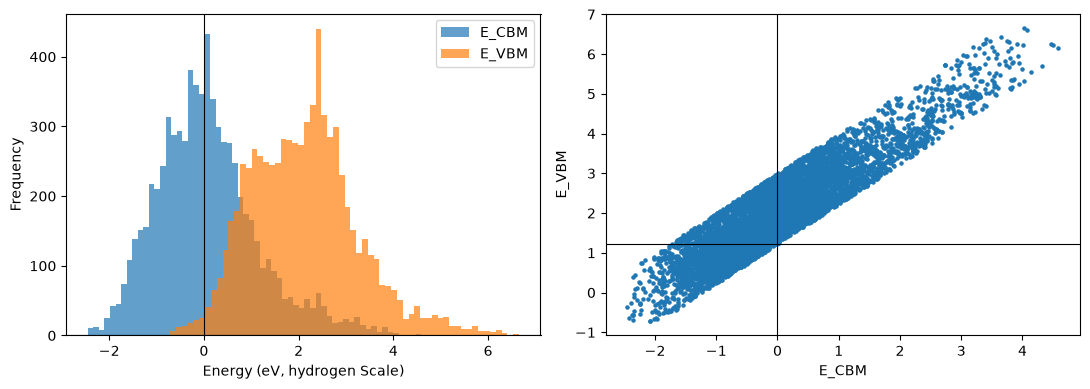

In [46]:
df.to_csv(OUT_PATH, index=False)
summary = {
    "saved_at": datetime.now().isoformat(timespec="seconds"),
    "input_file": IN_PATH.name,
    "rows": int(len(df)),
    "rows_without_chi": int(df["chi_mulliken"].isna().sum()),
    "E_e(eV)": E_FREE, 
    "formula": "E_CBM = chi - E_FREE - Eg/2 ; E_VBM  = E_CBM + Eg ; chi = geometric mean of atomic (IE + EA)/2",

}
(DATA_DIR / f"{OUT_PATH.stem}_summary.json").write_text(json.dumps(summary, indent=2))
print("Saved:", OUT_PATH)
print(json.dumps(summary, indent=2))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df["E_CBM"].plot.hist(bins=60, ax=axes[0], alpha=0.7, label="E_CBM")
df["E_VBM"].plot.hist(bins=60, ax=axes[0], alpha=0.7, label="E_VBM")
axes[0].axvline(0.0, color="k", lw=0.8); axes[0].axhline(1.23, color="k", lw=0.8)
axes[0].set_xlabel("Energy (eV, hydrogen Scale)"); axes[0].legend()
axes[1].scatter(df["E_CBM"], df["E_VBM"], s=5)
axes[1].axvline(0.0, color="k", lw=0.8); axes[1].axhline(1.23, color="k", lw=0.8)
axes[1].set_xlabel("E_CBM"); axes[1].set_ylabel("E_VBM")
plt.tight_layout()
plt.savefig(FIG_DIR / "edge_cal.png", dpi=200)
plt.show()


